# This notebook aims to help understand the reader on a deeper level what is happening inside my thesis. I also helps revisit information if I ever forget something and train methods used.

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
import copy
import os
from torch.utils.data import TensorDataset, DataLoader

In [2]:
# piece of code that was copied from my Deep Learning with Massively Parallel Acceleration Classes
print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
  print("GPU name:", torch.cuda.get_device_name(0))
  device = torch.device("cuda")
  !nvidia-smi
else:
  device = torch.device("cpu")

print("Selected device:", device)

PyTorch version: 2.7.0
CUDA available: False
Selected device: cpu


In [3]:
# orbits list stores the prefixes of all orbits of the Galileo spacecraft
# that are of my interest
orbits = ["ORB04", "ORB11", "ORB12", "ORB14", "ORB19", "ORB26"] # 04, 11, 12, 14, 19, 26

savefiles_prefix = "regular_"
folder_name = "_regular"

try:
    os.mkdir(folder_name)
except:
    print("File already exists")

orbits_preproc_data = []

# gets raw data from the csv files and both for training
# input - coordinates in EPHIO frame and
# output - magnetic field in each of those coordinates
# all of this data is is put into a nested list:
# orbits_preproc_data = [current_orbit_data, current_orbit_data, ...]
for i, orbit in enumerate(orbits):
    str = f"{orbits[i]}_EUR_EPHIO.csv"
    df = pd.read_csv(str)

    # input X, Y, Z coordinates
    X_raw = df[["X", "Y", "Z"]].values
    # output Magnetic Field Bx, By, Bz
    y_raw = df[["BX", "BY", "BZ"]].values

    # scales data to [-1, 1] for Tanh or sigmoid
    input_scaler = MinMaxScaler(feature_range=(-1, 1))
    output_scaler = MinMaxScaler(feature_range=(-1, 1))

    X_scaled = input_scaler.fit_transform(X_raw)
    y_scaled = output_scaler.fit_transform(y_raw)

    # to tensor
    X_tensor = torch.tensor(X_scaled, dtype=torch.float32).to(device) # Cuda czyni cuda
    y_tensor = torch.tensor(y_scaled, dtype=torch.float32).to(device) # tu też

    # data split
    X_train, X_val, y_train, y_val = train_test_split(X_tensor, y_tensor, test_size=0.2, random_state=67)

    orbits_preproc_data.append((X_raw, y_raw, X_train, y_train, X_val, y_val, input_scaler, output_scaler))
    print(orbits_preproc_data)

File already exists
[(array([[-2.64905,  3.52158, -0.05499],
       [-2.64806,  3.52093, -0.05498],
       [-2.64707,  3.52028, -0.05497],
       ...,
       [ 6.14709, -2.94102,  0.01595],
       [ 6.14801, -2.94175,  0.01596],
       [ 6.14801, -2.94175,  0.01596]], shape=(8775, 3)), array([[  74.68, -143.06, -442.02],
       [  73.45, -143.04, -439.09],
       [  73.02, -142.16, -442.27],
       ...,
       [  42.01, -201.4 , -395.89],
       [  40.66, -203.73, -395.85],
       [  40.66, -203.73, -395.85]], shape=(8775, 3)), tensor([[-0.0167,  0.0832, -0.1464],
        [ 0.5880, -0.5578,  0.5292],
        [-0.4715,  0.5241, -0.5743],
        ...,
        [ 0.7241, -0.7036,  0.6846],
        [-0.5601,  0.6048, -0.6476],
        [ 0.1497, -0.0909,  0.0351]]), tensor([[ 0.5145, -0.8647,  0.1713],
        [ 0.1075, -0.8395,  0.0727],
        [ 0.3818, -0.0870, -0.3927],
        ...,
        [ 0.0733, -0.8832, -0.0600],
        [ 0.3766, -0.1440, -0.3744],
        [ 0.1051, -0.7683,  0.0

In [4]:
# define the model

# model has most of SiLU activation functions instead of ReLU
# because it needs to be smooth and differentiable for PINN
# it is ended with Tanh af to output values in
# the range of [-1, 1] for the scaled magnetic field data
class PINN(nn.Module):
  def __init__(self):
    super(PINN, self).__init__()
    self.net = nn.Sequential(
      # input layer with 3 neurons for X, Y, Z coordinates
      nn.Linear(3, 64),
      nn.SiLU(),
      nn.Linear(64, 128),
      nn.SiLU(),
      nn.Linear(128, 128),
      nn.SiLU(),
      nn.Linear(128, 128),
      nn.SiLU(),
      nn.Linear(128, 128),
      nn.SiLU(),
      nn.Linear(128, 64),
      nn.Tanh(),
      # output layer with 3 neurons for Bx, By, Bz magnetic field components
      nn.Linear(64, 3)
      )

  def forward(self, x):
    return self.net(x)

In [5]:
def physics_loss_function(model, x_collocation):
  x_collocation.requires_grad = True

  # input collocation points into the PINN model
  b_pred = model(x_collocation)

  bx = b_pred[:, 0].unsqueeze(1)
  by = b_pred[:, 1].unsqueeze(1)
  bz = b_pred[:, 2].unsqueeze(1)

  # create arrays that will hold values of all combinations of partial derivatives
  grads_bx = torch.autograd.grad(bx, x_collocation, grad_outputs=torch.ones_like(bx), create_graph=True)[0]
  dbx_dx, dbx_dy, dbx_dz = grads_bx[:, 0], grads_bx[:, 1], grads_bx[:, 2]

  grads_by = torch.autograd.grad(by, x_collocation, grad_outputs=torch.ones_like(by), create_graph=True)[0]
  dby_dx, dby_dy, dby_dz = grads_by[:, 0], grads_by[:, 1], grads_by[:, 2]

  grads_bz = torch.autograd.grad(bz, x_collocation, grad_outputs=torch.ones_like(bz), create_graph=True)[0]
  dbz_dx, dbz_dy, dbz_dz = grads_bz[:, 0], grads_bz[:, 1], grads_bz[:, 2]

  # Now calculating the loss. It has 2 parts: divergence part and curl part.
  # Both of them need to be equal to 0 and that's why they are used in loss function.
  # For curl, the result should be in the form of a vector, but here we need both scalars,
  # so the vector components are added together (their squares to be precise).

  # first term - Gauss's law for magnetism div(B) = 0 -> divergence free -> no monopoles
  divergence = dbx_dx + dby_dy + dbz_dz
  div_loss = torch.mean(divergence**2)

  # second term - Ampere's law curl(B) = 0 -> irrotational -> current free
  curlx = dbz_dy - dby_dz
  curly = dbx_dz - dbz_dx
  curlz = dby_dx - dbx_dy
  curl_loss = torch.mean(curlx**2 +curly**2 + curlz**2)

  return div_loss + curl_loss
#############################

# function that generates random collocation points
def get_collocation_points(num_points=3000, bounds=(-1, 1), device=device):
  points = (bounds[1] - bounds[0] * torch.rand(num_points, 3, device=device) + bounds[0])
  return points.to(device)

model = PINN().to(device)
x_collocation = get_collocation_points()
physics_loss_function(model, x_collocation)


tensor(2.4247e-06, grad_fn=<AddBackward0>)

In [6]:
epochs = 50
batch_size = 512
lambda_physics = 0.7
no_collocation_points = 300

# the commented append underneath is just copied from before
# (I wanted to know in what order I saved those values)
#orbits_preproc_data.append(
#(X_raw, y_raw, X_train, y_train, X_val, y_val, input_scaler, output_scaler))
orbits_models_data = []


# goes through each orbit -> for each orbit there needs to be a separate model
# or otherwise the it all goes to shit (tried)
# each orbit has different physics
# (angle at which Galileo flies by Europa, Jupiter magnetic field bg, etc.)
for i, orbit_data in enumerate(orbits_preproc_data):
  model = PINN().to(device)
  # I am using Adam optimizer but could be sth different
  # I have not spent enough time to determine, whether some different
  # optimizer would be better
  optimizer = optim.Adam(model.parameters(), lr=1e-3)
  criterion_data = nn.MSELoss()

  print(f"Training on orbit: {orbits[i]}")

  # index 2 and 3 are corresponding to train values for orbits_preproc_data
  X_train, y_train = orbit_data[2], orbit_data[3]

  train_dataset = TensorDataset(X_train, y_train)
  train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)

  loss_history = {'data': [], 'physics': []}

  # iterating over epochs
  for epoch in range(epochs):
    model.train()

    epoch_physics_loss = 0.0
    epoch_data_loss = 0.0

    # iterating over batches
    for batch_X, batch_y in train_loader:
      optimizer.zero_grad()

      # data loss
      # using defined model to get pred_data and data_loss uses MSEloss
      # between predicted data and actual batch_y data
      pred_data = model(batch_X)
      data_loss = criterion_data(pred_data, batch_y)

      # physics loss
      # getting random points throughout the function to test whether
      # they do not violate two maxwell equations defined before
      # b_pred is used inside the physics_loss_function
      x_phys = get_collocation_points(num_points=no_collocation_points, device=device)
      physics_loss = physics_loss_function(model, x_phys)

      loss_total = data_loss + physics_loss * lambda_physics

      loss_total.backward()
      optimizer.step()

      epoch_data_loss += data_loss.item()
      epoch_physics_loss += physics_loss.item()

    # aveeraging data losses over batches cuz adding them makes no sense
    # and taking just one (e.g. first one) might not be representative
    avg_data_loss = epoch_data_loss / len(train_loader)
    avg_physics_loss = epoch_physics_loss / len(train_loader)

    # tracking the loss histories (mainly for visualizations)
    loss_history['data'].append(avg_data_loss)
    loss_history['physics'].append(avg_physics_loss)


    if (epoch + 1) % (epochs/10) == 0:
      print(f"Orbit: {orbits[i]} | Epoch: {epoch+ 1}/{epochs} | Data Loss: {avg_data_loss:.5f} | Physics Loss: {avg_physics_loss:.5f}")

  # coping the model -> using deepcopy just in case because
  # I don't want to mess with the actual model
  orbits_models_data.append((copy.deepcopy(model.state_dict()), loss_history))




Training on orbit: ORB04
Orbit: ORB04 | Epoch: 5/50 | Data Loss: 0.03946 | Physics Loss: 0.00286
Orbit: ORB04 | Epoch: 10/50 | Data Loss: 0.02716 | Physics Loss: 0.00138
Orbit: ORB04 | Epoch: 15/50 | Data Loss: 0.01557 | Physics Loss: 0.00210
Orbit: ORB04 | Epoch: 20/50 | Data Loss: 0.00861 | Physics Loss: 0.00096
Orbit: ORB04 | Epoch: 25/50 | Data Loss: 0.00817 | Physics Loss: 0.00054
Orbit: ORB04 | Epoch: 30/50 | Data Loss: 0.00784 | Physics Loss: 0.00042
Orbit: ORB04 | Epoch: 35/50 | Data Loss: 0.00772 | Physics Loss: 0.00041
Orbit: ORB04 | Epoch: 40/50 | Data Loss: 0.00754 | Physics Loss: 0.00034
Orbit: ORB04 | Epoch: 45/50 | Data Loss: 0.00736 | Physics Loss: 0.00035
Orbit: ORB04 | Epoch: 50/50 | Data Loss: 0.00719 | Physics Loss: 0.00033
Training on orbit: ORB11
Orbit: ORB11 | Epoch: 5/50 | Data Loss: 0.05077 | Physics Loss: 0.00662
Orbit: ORB11 | Epoch: 10/50 | Data Loss: 0.03058 | Physics Loss: 0.00351
Orbit: ORB11 | Epoch: 15/50 | Data Loss: 0.02342 | Physics Loss: 0.00143
Orb

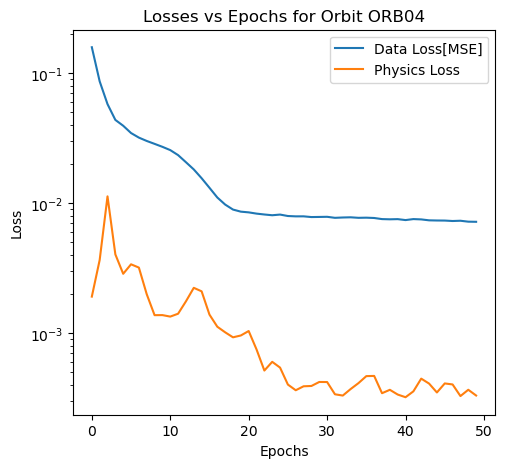

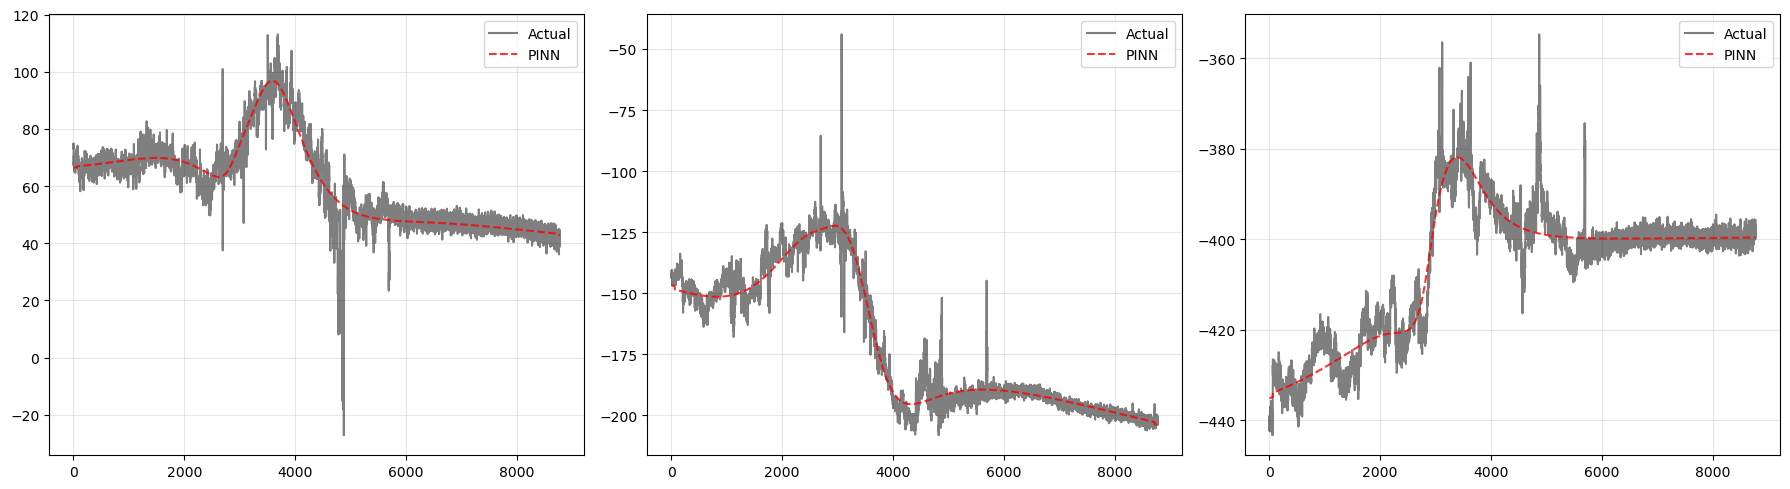

PINN Model for ORB04 saved.


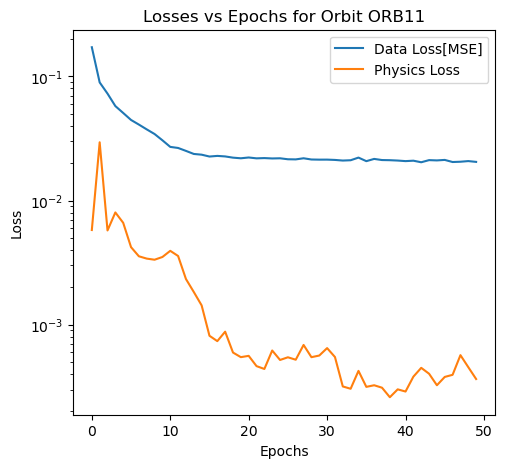

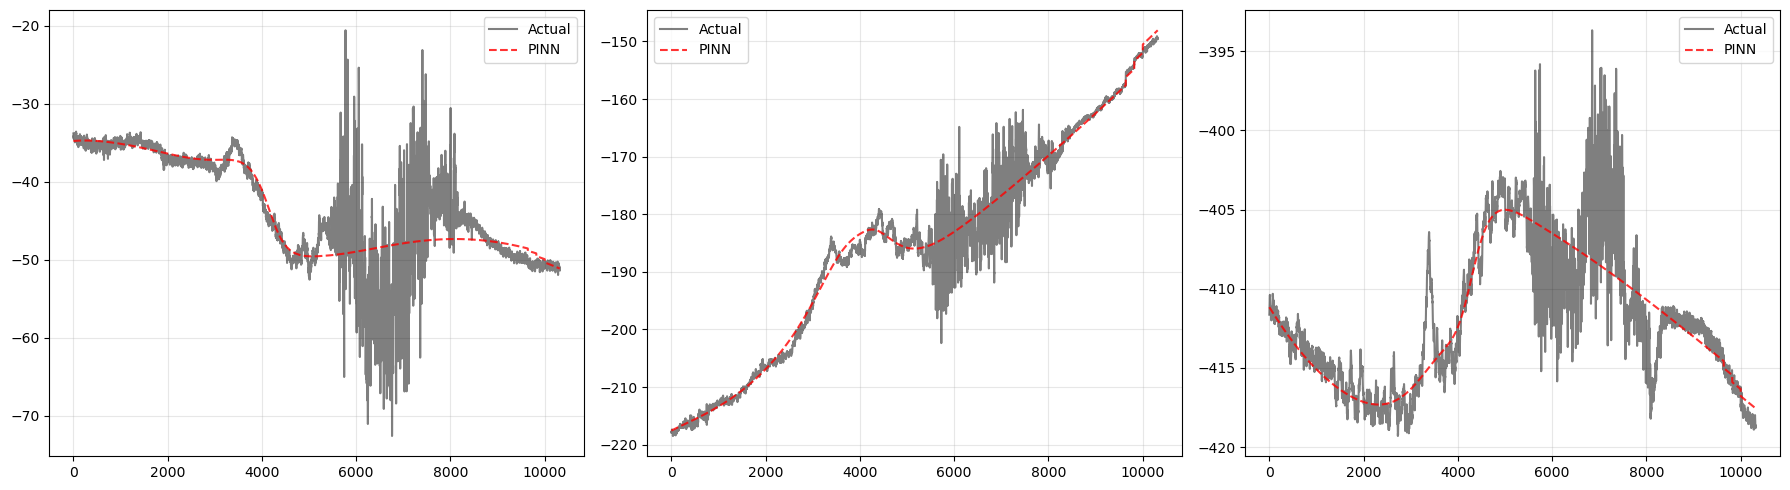

PINN Model for ORB11 saved.


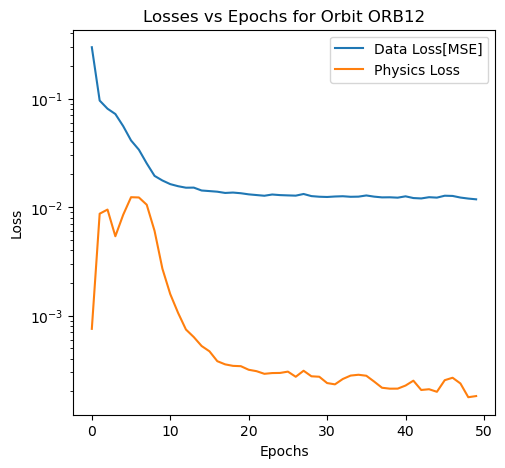

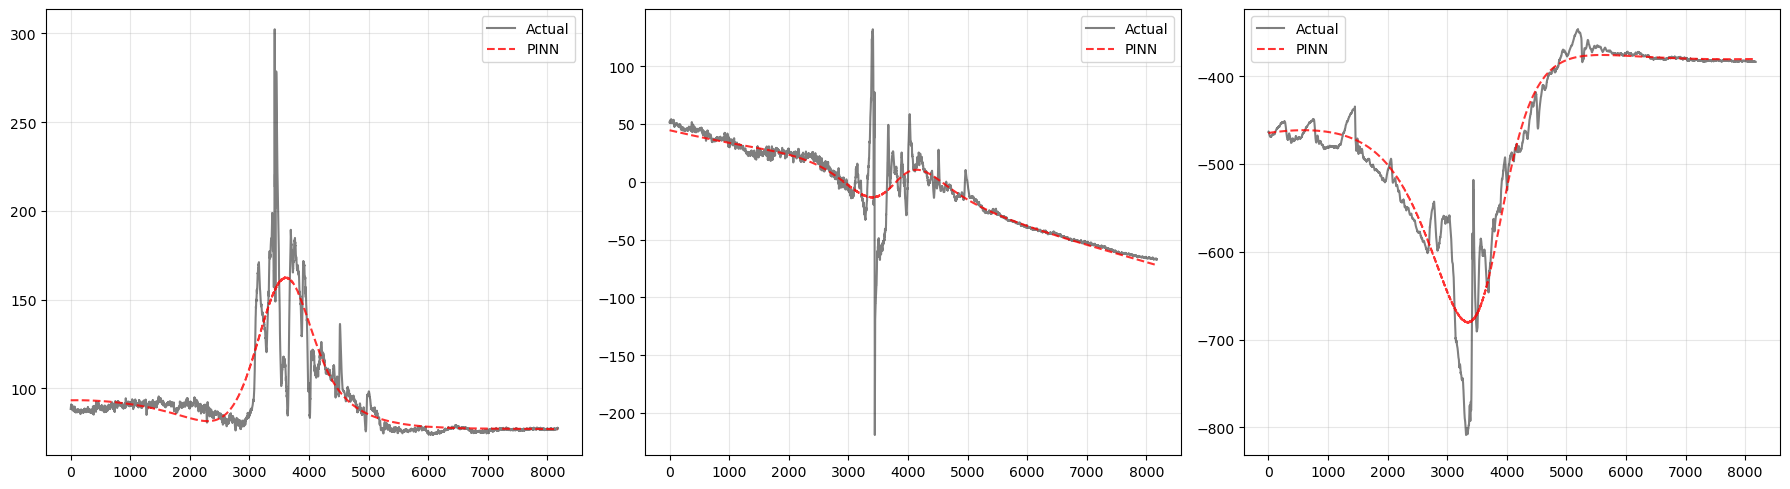

PINN Model for ORB12 saved.


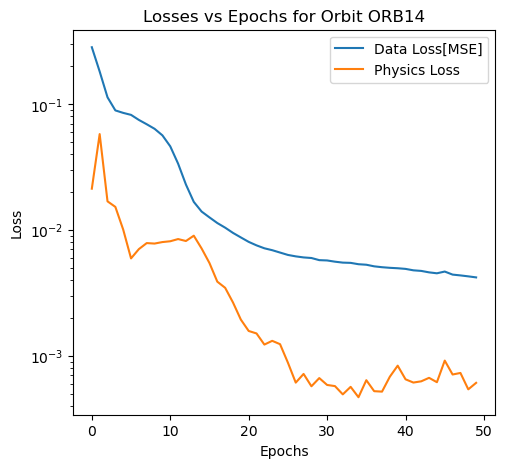

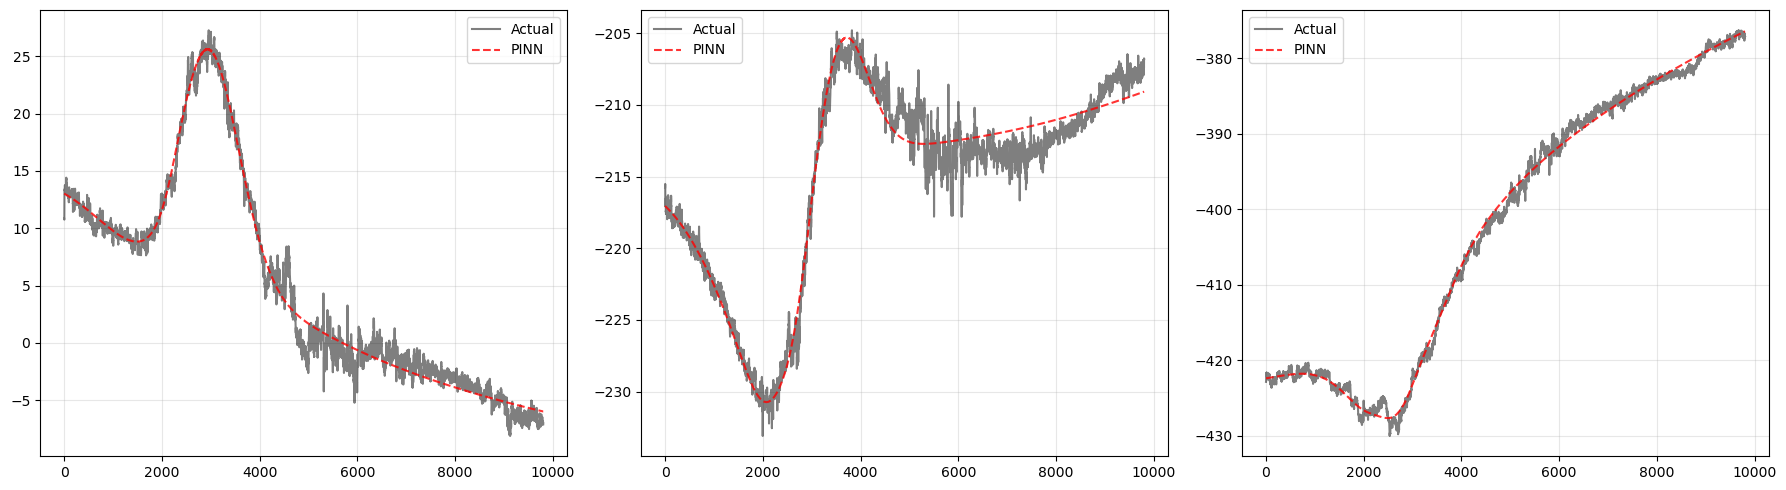

PINN Model for ORB14 saved.


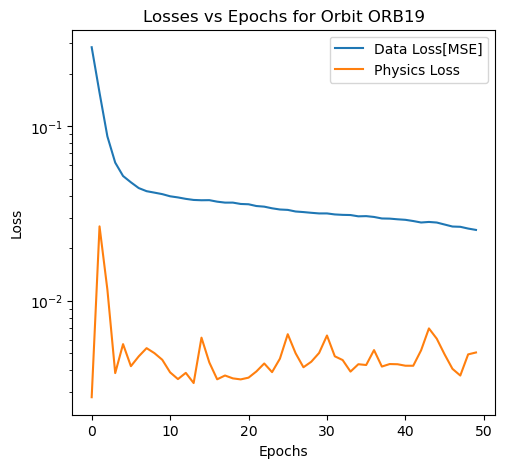

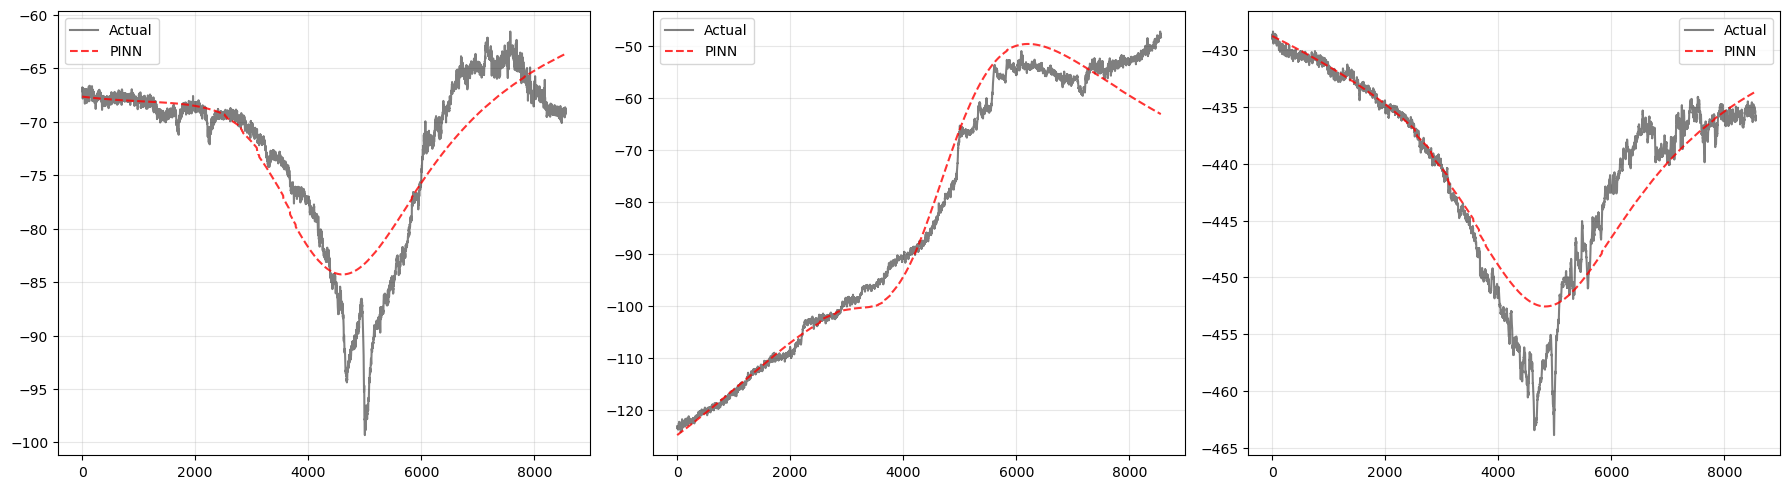

PINN Model for ORB19 saved.


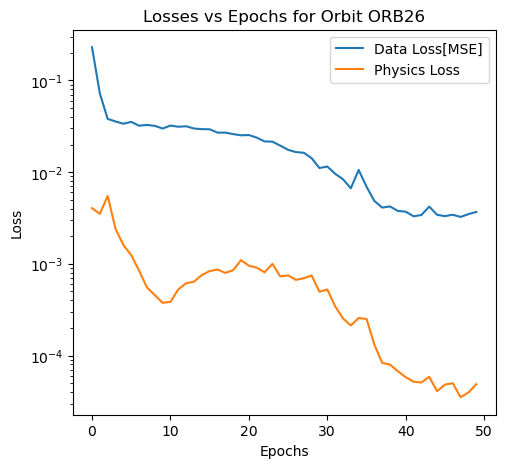

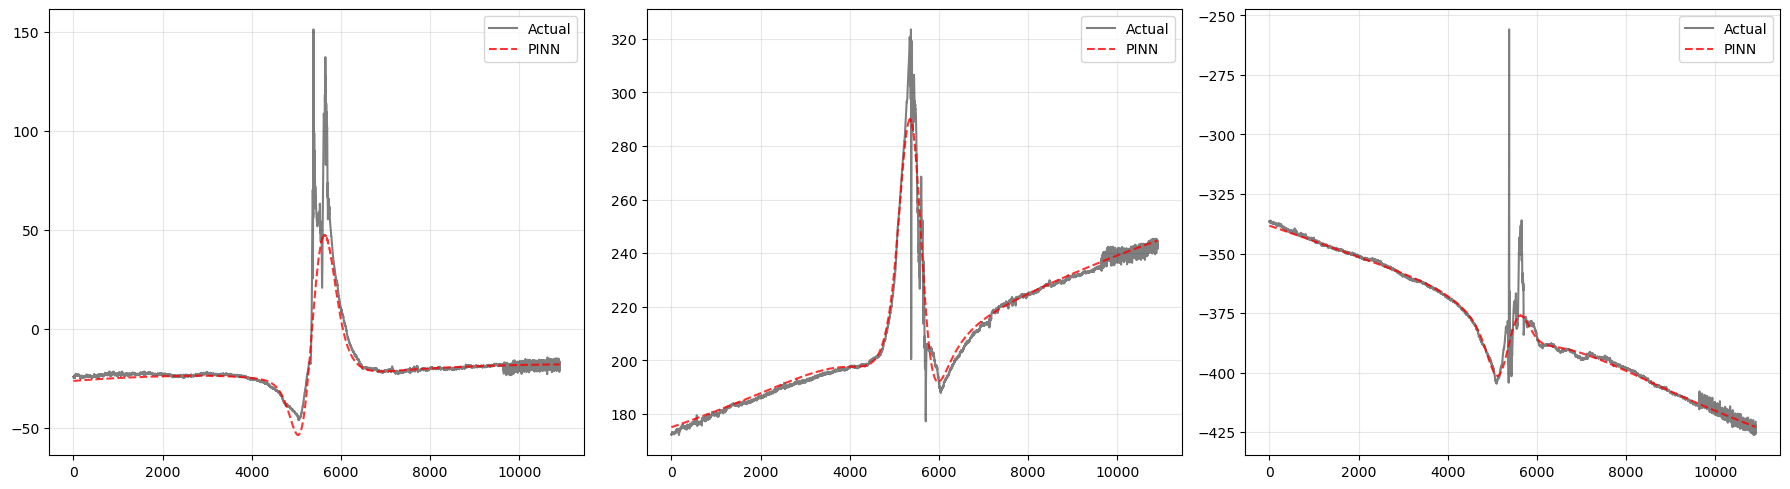

PINN Model for ORB26 saved.


In [7]:
for i, (orbit_packet, model_packet) in enumerate(zip(orbits_preproc_data, orbits_models_data)):

  X_raw, y_raw, X_train, y_train, X_val, y_val, input_scaler, output_scaler = orbit_packet

  model_state, loss_history = model_packet

  model = PINN().to(device)
  model.load_state_dict(model_state)
  model.eval()

  plt.figure(figsize=(12, 5))

  # loss plot
  plt.subplot(1, 2, 1)
  plt.plot(loss_history['data'], label='Data Loss[MSE]')
  plt.plot(loss_history['physics'], label="Physics Loss")
  plt.yscale("log")
  plt.xlabel("Epochs")
  plt.ylabel("Loss")
  plt.title(f"Losses vs Epochs for Orbit {orbits[i]}")
  plt.legend()

  # prediction plot
  with torch.no_grad():
    X_scaled_current = input_scaler.transform(X_raw)
    X_tensor_current = torch.tensor(X_scaled_current, dtype=torch.float32).to(device)

    full_pred_scaled = model(X_tensor_current)
    full_pred = output_scaler.inverse_transform(full_pred_scaled.cpu().numpy())  # had to move it back to cpu before numpy or scikit-learn (it cried otherwise)

    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    components = ["BX (Corotation)", "BY (To Jupiter)", "BZ (North-South)"]

    for k in range(3):
      axes[k].plot(y_raw[:, k], "k-", alpha=0.5, label="Actual")
      axes[k].plot(full_pred[:, k], "r--", alpha=0.8, label="PINN")
      axes[k].legend()
      axes[k].grid(True, alpha=0.3)

    plt.tight_layout()
    # plt.savefig(f"pinn_results_{orbits[i]}_3components.png")
    plt.savefig(f"{folder_name}/{savefiles_prefix}_{orbits[i]}_3components.png")
    plt.show()

  # Save model
  torch.save(model.state_dict(), f"{folder_name}/europa_pinn_model_{orbits[i]}.pth")
  print(f"PINN Model for {orbits[i]} saved.")
